# 04 · Measure surfaces and prepare map layers

**Goal:** calculate geometry properties and build linked 2D/3D assets for the later Streamlit demo. This stage does not estimate solar exposure or panel output.

Run with the repository's `.venv` Python environment. In VS Code choose **Select Kernel → Python Environments → .venv**. Run from the repository root or `sra_notebooks`.

Roadmap: Inspect → Parse → Transform → **Analyze** → Visualize. The analysis code is reusable; the notebook explains the results. Your existing Streamlit presentation page is unchanged.

In [1]:
from pathlib import Path
from dataclasses import asdict
import tempfile
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from IPython.display import display
from gismo_2026_fall_hackathon.citygml import iter_buildings
from gismo_2026_fall_hackathon.meshes import buildings_to_mesh
from gismo_2026_fall_hackathon.surface_analysis import measure_surfaces, export_layers

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists() and (ROOT.parent / "pyproject.toml").exists():
    ROOT = ROOT.parent
GML_FILE = ROOT / "data/DA_WISE_GML/DA_WISE_GMLs/DA1_3D_Buildings_Merged.gml"
SAMPLE_SIZE = 25
Z_SCALE = 1.0  # provisional: source Z is assumed to match source XY units
Z_UNITS_VERIFIED = False  # change only when the conversion has been established
assert isinstance(SAMPLE_SIZE, int) and SAMPLE_SIZE > 0
buildings = list(iter_buildings(GML_FILE, limit=SAMPLE_SIZE))
mesh_result = buildings_to_mesh(buildings, z_scale=Z_SCALE)
analysis = measure_surfaces(mesh_result, dataset_id=GML_FILE.name,
                            z_units_verified=Z_UNITS_VERIFIED)
print(f"{len(buildings)} input buildings; {len(analysis.surfaces)} meshed source polygons")
print(f"{len(analysis.roofs)} roof projections; {len(analysis.buildings)} building records")
print("All physical measurements provisional:", analysis.surfaces.measurements_provisional.all())

25 input buildings; 337 meshed source polygons
56 roof projections; 25 building records
All physical measurements provisional: True


## 1. What is being measured?

Each row describes one **source polygon**, not one triangle. A semantic surface can have multiple polygon rows. Triangle areas are summed; normals are combined with area weighting.

| Field | Meaning |
|---|---|
| `area_m2` | 3D triangle area, converted from the horizontal CRS unit into square metres after applying the explicit Z scale |
| `projected_area_m2` | Area occupied in a top-down XY projection; distinct from 3D surface area |
| `tilt_deg` | Plane inclination: horizontal = 0°, vertical = 90°; independent of winding |
| `azimuth_true_deg` | Direction of the outward normal's horizontal component, clockwise from true north; withheld when direction is unverified |
| `normal_status` | Conservative shell/orientation check result |
| `measurements_provisional` | True until the Z-unit conversion is verified |
| `source_has_extraction_issues` | Indicates that source parsing/meshing issues exist; measurements cover successfully meshed polygons only |

A flat roof has no unique aspect: its azimuth is missing, not zero. That says nothing about which direction installed panels could face. Grid north in State Plane coordinates differs from true north; compass directions here are calculated geodetically at the polygon's location.

**Units:** the conversion to m² does not verify the Z scale. Both area and inclination can change if Z units differ from the current assumption. Vertical datum is also unverified, though a constant vertical offset does not change surface area or slope.

In [2]:
columns = ["feature_key", "building_id", "surface_id", "surface_kind", "polygon_index",
           "area_m2", "projected_area_m2", "tilt_deg", "azimuth_true_deg", "normal_status",
           "measurements_provisional"]
display(analysis.surfaces[columns].head(12))
display(analysis.surfaces.groupby("surface_kind").agg(
    polygons=("feature_key", "size"), area_m2=("area_m2", "sum"),
    minimum_tilt=("tilt_deg", "min"), maximum_tilt=("tilt_deg", "max")))
# Polygon attributes are attached to mesh cells through the same feature key.
assert set(analysis.mesh.cell_data["feature_key"]) == set(analysis.surfaces.feature_key)
print("2D/3D linkage verified")

,feature_key,building_id,surface_id,surface_kind,polygon_index,area_m2,projected_area_m2,tilt_deg,azimuth_true_deg,normal_status,measurements_provisional
0,5ad2df142e4601ac8bd0000d,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_G73EI5D84XNG6BTW7RBQKARYXFGFBMWRIZET,RoofSurface,0,133.797139,133.797139,0.0,NaN,closed_consistent_positive_volume,True
1,f247b03789be6990914f2bfe,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_AWDTFCCAUHPYIQ209FIFPFQDY87RB58G6AVL,GroundSurface,0,133.797139,133.797139,0.0,NaN,closed_consistent_positive_volume,True
2,6de775cbd02b1b319ea7f6b6,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_NSLH7QDQZR6UT6SCR8E5FA4GFU9ZII2I5RMQ,WallSurface,0,91.811684,0.000000,90.0,15.057510,closed_consistent_positive_volume,True
3,ac6363f02eb5f7f2535b1105,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_4AI8CANHCM8FM5Z760FNXECMROHQZXZCTCHQ,WallSurface,0,5.383819,0.000000,90.0,285.057997,closed_consistent_positive_volume,True
4,46ed93f2fc8fac662e0b3542,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_0F3FXXE2W4MMT4MEM82Z85RY26SOX5VKYIH0,WallSurface,0,33.338737,0.000000,90.0,285.056730,closed_consistent_positive_volume,True
5,4ba649c30683e79fd149345a,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_790AAJ0WB474LV0UKSS5YEM0F0E0JCYLXWGM,WallSurface,0,4.335459,0.000000,90.0,285.060013,closed_consistent_positive_volume,True
6,2048d50f43bd662b0e4373c7,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_I2ZYF4W88XCCFBAF0LB2X94JF9N8FWGZONMR,WallSurface,0,91.811684,0.000000,90.0,195.057494,closed_consistent_positive_volume,True
7,3cfa5bd71a6972763615cc8e,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_23Z3SO1RXCUICSULUNZI7PTGRX2MQNY2YSN7,WallSurface,0,43.058014,0.000000,90.0,105.057345,closed_consistent_positive_volume,True
8,a60a52671e725288df036c44,gml_VHKIINWDOF6WB4EAYEUNKTM4WOAJO2TUFXZN,gml_DQAU2Q1M1FLWJXDU7AWB4PV3MMZVVMROF07H,RoofSurface,0,8.566833,8.566833,0.0,NaN,unverified_open_or_nonmanifold,True
9,42689f127f2f7ac6490cc55f,gml_VHKIINWDOF6WB4EAYEUNKTM4WOAJO2TUFXZN,gml_DAU42ADRDOA0Z8WFAYSX4HHQ0F0OY6QS05Q6,RoofSurface,0,91.367418,91.367418,0.0,NaN,unverified_open_or_nonmanifold,True


,polygons,area_m2,minimum_tilt,maximum_tilt
surface_kind,,,,
GroundSurface,25,4068.380956,0.0,0.0
RoofSurface,56,4068.380956,0.0,0.0
WallSurface,256,10351.942356,90.0,90.0


2D/3D linkage verified


## 2. Check direction before using azimuth

The source's ring winding is preserved, not silently flipped. For each building/part owner, the analysis checks that every undirected edge is shared by two oppositely directed triangles and that each connected shell has positive signed volume. Roof normals must point upward and ground normals downward; excessive variation between triangle normals is also flagged.

These are conservative checks, not proof against self-intersections or nested shells. Exact edge matching can fail on T-junctions or almost-equal vertices even when a model looks closed. We do not snap or repair coordinates here.

When a check fails, area and plane inclination remain available but compass azimuth is withheld. Normal uncertainty and provisional vertical units are **separate** flags. Horizontal surfaces have no azimuth even when the shell checks pass.

In [3]:
display(analysis.surfaces.groupby(["normal_status", "surface_kind"]).size().rename("polygons").to_frame())
print(f"{len(analysis.issues)} extraction/orientation flags")
if analysis.issues:
    issues = pd.DataFrame([asdict(i) for i in analysis.issues])
    display(issues.value_counts("message").rename("count").to_frame())
    display(issues.head(8))
else:
    print("No flags in this sample; this does not establish citywide validity.")

polygons
normal_status                     surface_kind           
closed_consistent_positive_volume GroundSurface         1
                                  RoofSurface           1
                                  WallSurface           6
unverified_open_or_nonmanifold    GroundSurface        24
                                  RoofSurface          55
                                  WallSurface         250

329 extraction/orientation flags


,count
message,
Azimuth withheld: unverified_open_or_nonmanifold,329


,context,message
0,a60a52671e725288df036c44,Azimuth withheld: unverified_open_or_nonmanifold
1,42689f127f2f7ac6490cc55f,Azimuth withheld: unverified_open_or_nonmanifold
2,482637437b54343a607b9cca,Azimuth withheld: unverified_open_or_nonmanifold
3,7ba0106836d961f425f4fa75,Azimuth withheld: unverified_open_or_nonmanifold
4,ba331d401464fb9dc893cf3e,Azimuth withheld: unverified_open_or_nonmanifold
5,afa0e1ad28981df0e37d2cd4,Azimuth withheld: unverified_open_or_nonmanifold
6,d0acc6c4d75e32591918e30c,Azimuth withheld: unverified_open_or_nonmanifold
7,951554a9e7124f03f770a411,Azimuth withheld: unverified_open_or_nonmanifold


## 3. Build portable geospatial layers

The analysis returns two GeoDataFrames in the **source projected CRS**:

- `analysis.roofs`: XY projections of meshed roof polygons, carrying their 3D measurements and source keys. Holes are preserved through the projected triangle union.
- `analysis.buildings`: footprints from the union of meshed GroundSurface projections, plus total roof area. Missing ground geometry is explicitly flagged; we do not substitute a roof outline or convex hull.

`roof_area_m2` sums actual 3D roof geometry, while `roof_projected_area_m2` is a top-down union that avoids counting overlapping roof projections twice. Footprint area comes only from ground projections. All are based on the extracted mesh, so inspect exclusions before interpreting completeness.

`dataset_id`, `building_key`, and `feature_key` link the source file, 2D layers, surface table, and 3D mesh. Building index links back to the parsed `buildings` list when you need original BIN or other metadata. GeoJSON exports are transformed to longitude/latitude for browser maps; analysis remains in projected coordinates.

The plots below focus on the first available footprint so individual polygons stay readable. The first 25 source records are not necessarily spatial neighbors; the tables and exports still contain the full sample.

,dataset_id,building_key,building_id,building_index,footprint_status,footprint_area_m2,roof_area_m2,roof_projected_area_m2,measurements_provisional,z_scale,source_has_extraction_issues,orientation_flag_count
0,DA1_3D_Buildings_Merged.gml,5a3051a36c6fa5b59ede4c38,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,0,ground_projection,133.797139,133.797139,133.797139,True,1.0,False,0
1,DA1_3D_Buildings_Merged.gml,5f61e6ec8f98c5e01418dd4d,gml_VHKIINWDOF6WB4EAYEUNKTM4WOAJO2TUFXZN,1,ground_projection,99.934251,99.934251,99.934251,True,1.0,False,11
2,DA1_3D_Buildings_Merged.gml,8c99cfb44ee6193f01c8132c,gml_A6J4L0RIDQ1932MHI20F9XRU3YDRKT44WAIL,2,ground_projection,233.109714,233.109714,233.109714,True,1.0,False,15
3,DA1_3D_Buildings_Merged.gml,012e37425e5338168cc98658,gml_YJR00O3LS8E92KBJZV8SLHZ0N9C10ZXBKUJM,3,ground_projection,180.733971,180.733971,180.733971,True,1.0,False,14
4,DA1_3D_Buildings_Merged.gml,82864ec2a1692664f705d502,gml_A5PXVHPLMVNN56TZAT3PEHBRCSFVQPWGMMEF,4,ground_projection,181.839221,181.839221,181.839221,True,1.0,False,20


Layer CRS: EPSG:2263
Missing footprint geometries: 0


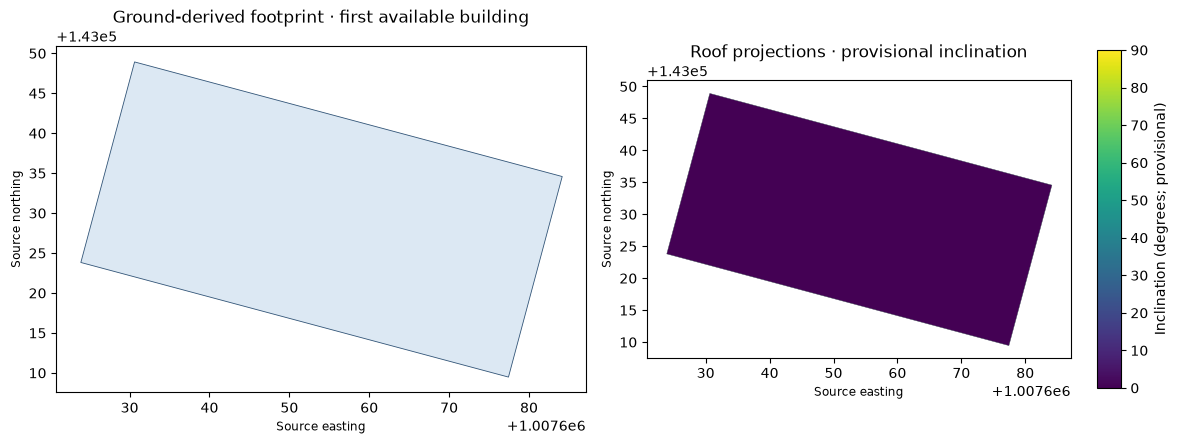

In [4]:
display(analysis.buildings.drop(columns="geometry").head())
print("Layer CRS:", analysis.buildings.crs)
print("Missing footprint geometries:", analysis.buildings.geometry.isna().sum())
assert not analysis.roofs.geometry.has_z.any()
assert analysis.roofs.geometry.is_valid.all()
assert analysis.buildings.geometry.dropna().is_valid.all()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
footprints = analysis.buildings[analysis.buildings.geometry.notna()]
plot_footprints = footprints.head(1)
plot_roofs = analysis.roofs[analysis.roofs.building_key.isin(plot_footprints.building_key)]
if not plot_footprints.empty:
    plot_footprints.plot(ax=axes[0], facecolor="#dce8f3", edgecolor="#315477", linewidth=0.6)
axes[0].set_title("Ground-derived footprint · first available building")
if not plot_roofs.empty:
    plot_roofs.plot(ax=axes[1], column="tilt_deg", cmap="viridis", vmin=0, vmax=90,
                        edgecolor="#374151", linewidth=0.3, legend=True,
                        legend_kwds={"label": "Inclination (degrees; provisional)"})
axes[1].set_title("Roof projections · provisional inclination")
for ax in axes:
    ax.set(xlabel="Source easting", ylabel="Source northing")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 4. Preview the Folium connection

This bounded map preview uses the same kind of GeoJSON layer that can feed the existing Streamlit/Folium placeholder. It is a 2D overview; detailed walls and mesh faces remain in the 3D asset. Building tooltips expose the key needed to link a map selection to a detailed view.

Only the first building is shown here to keep the saved notebook compact; the full sample is available in `analysis.buildings` and in exports. Background map tiles require an internet connection. Blue means footprint, not solar suitability.

In [5]:
preview = footprints.head(1).to_crs("EPSG:4326")
if preview.empty:
    print("No ground-derived footprint available to map in this sample.")
else:
    xmin, ymin, xmax, ymax = preview.total_bounds
    browser_map = folium.Map(location=[(ymin + ymax) / 2, (xmin + xmax) / 2], zoom_start=19)
    folium.GeoJson(
        data=json.loads(preview.to_json()), name="Building footprint",
        style_function=lambda feature: {"color": "#315477", "weight": 2, "fillOpacity": 0.3},
        tooltip=folium.GeoJsonTooltip(
            fields=["building_id", "building_key", "roof_area_m2", "measurements_provisional"],
            aliases=["Source building", "Linked building key", "Roof area (m²)", "Provisional measurements"]),
    ).add_to(browser_map)
    browser_map.fit_bounds([[ymin, xmin], [ymax, xmax]])
    display(browser_map)

## 5. Verify exports without changing the dataset

The export helper writes a **new** directory and refuses to overwrite an existing one. This cell checks exports in a temporary directory, then removes them. It does not leave files in the repository.

- `layers.gpkg`: projected `buildings` and `roofs` layers for GIS workflows.
- `buildings.geojson`, `roofs.geojson`: longitude/latitude layers for a bounded web map.
- `surfaces.csv`: per-polygon measurements and source keys.
- `surfaces.vtp`: labeled 3D mesh with the same feature keys and measurements.
- `issues.csv`: extraction and orientation flags.

Projected map geometries are genuinely 2D. The detailed 3D mesh retains the Stage 3 origin and scale metadata and must be positioned using those values.

In [6]:
with tempfile.TemporaryDirectory() as temp:
    output = export_layers(analysis, Path(temp) / "stage4")
    saved_layers = gpd.list_layers(output / "layers.gpkg")
    display(saved_layers)
    reloaded = gpd.read_file(output / "buildings.geojson")
    assert set(reloaded.building_key) == set(analysis.buildings.building_key)
    assert reloaded.crs.to_epsg() == 4326
    print("Verified exports:", ", ".join(sorted(p.name for p in output.iterdir())))

,name,geometry_type
0,buildings,Polygon
1,roofs,Polygon


Verified exports: buildings.geojson, issues.csv, layers.gpkg, roofs.geojson, surfaces.csv, surfaces.vtp


### Save durable outputs when ready

Choose a new output directory and run:

```python
export_layers(analysis, ROOT / "outputs" / "stage4_da1")
```

The source CityGML stays unchanged. For browser use, keep the selection bounded rather than loading all of NYC as GeoJSON.

### Stage 4 result

We have area, inclination, conditionally verified compass orientation, and linked map layers. These are geometry measurements, **not a solar suitability score**. No weather data, solar position, irradiance model, or shadow tracing has been added.

For Stage 5, the presentation page can show slides beside a compact demo, and a second page can offer the full exploration interface. Folium can consume the 2D GeoJSON layers; a 3D renderer can consume derived mesh geometry with the same keys. No Streamlit app files are modified in this stage.

References: [pyproj geodetic bearings](https://pyproj4.github.io/pyproj/stable/api/geod.html), [GeoPandas file export](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.to_file.html).